In [ ]:
# Importar librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Datasets
from sklearn.datasets import load_wine, load_iris, make_moons

# Preprocesamiento
from sklearn.preprocessing import StandardScaler

# Algoritmos
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

# Métricas
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Reducción de dimensiones
from sklearn.decomposition import PCA

# Clustering jerárquico
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuración de gráficos
plt.style.use('default')

print("Librerías importadas correctamente")

Librerías importadas correctamente


# **EJERCICIO 1. K-MEANS – SEGMENTACIÓN MEDIANTE CENTROIDES**

In [ ]:
# ==========================================
# EJERCICIO 1: K-MEANS - DATASET WINE
# ==========================================

# Importar librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [ ]:
# Cargar el dataset Wine
wine = load_wine()

# Crear DataFrame con las variables predictoras
X = pd.DataFrame(wine.data, columns=wine.feature_names)

# Mostrar las primeras filas
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
# Número de registros y variables
print("Número de registros:", X.shape[0])
print("Número de variables:", X.shape[1])

# Información general
print("\nInformación del dataset:")
X.info()

# Tipo de variables
print("\nTipos de variables:")
print(X.dtypes)

# Características principales
print("\nNombres de las variables:")
print(X.columns.tolist())

Número de registros: 178
Número de variables: 13

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    fl

El conjunto de datos Wine contiene 178 registros y 13 variables predictoras de tipo numérico. Estas variables representan características físico-químicas de las muestras de vino, como alcohol, ácido málico, cenizas, alcalinidad de las cenizas, magnesio, fenoles, flavonoides, intensidad del color y prolina.

In [ ]:
# Verificar valores nulos
print("Valores nulos por variable:")
print(X.isnull().sum())

# Total de valores nulos
print("\nTotal de valores nulos:", X.isnull().sum().sum())

Valores nulos por variable:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total de valores nulos: 0


Se realizó una revisión de los valores faltantes en las 13 variables del conjunto de datos. Esta comprobación permite identificar si es necesario aplicar algún procedimiento de imputación antes de ejecutar el algoritmo.

In [ ]:
# Estadísticas descriptivas
X.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Las estadísticas descriptivas permiten observar el comportamiento de las variables mediante sus valores mínimos, máximos, promedios y desviaciones estándar. Se pueden identificar diferencias importantes entre las escalas de medición de las características.

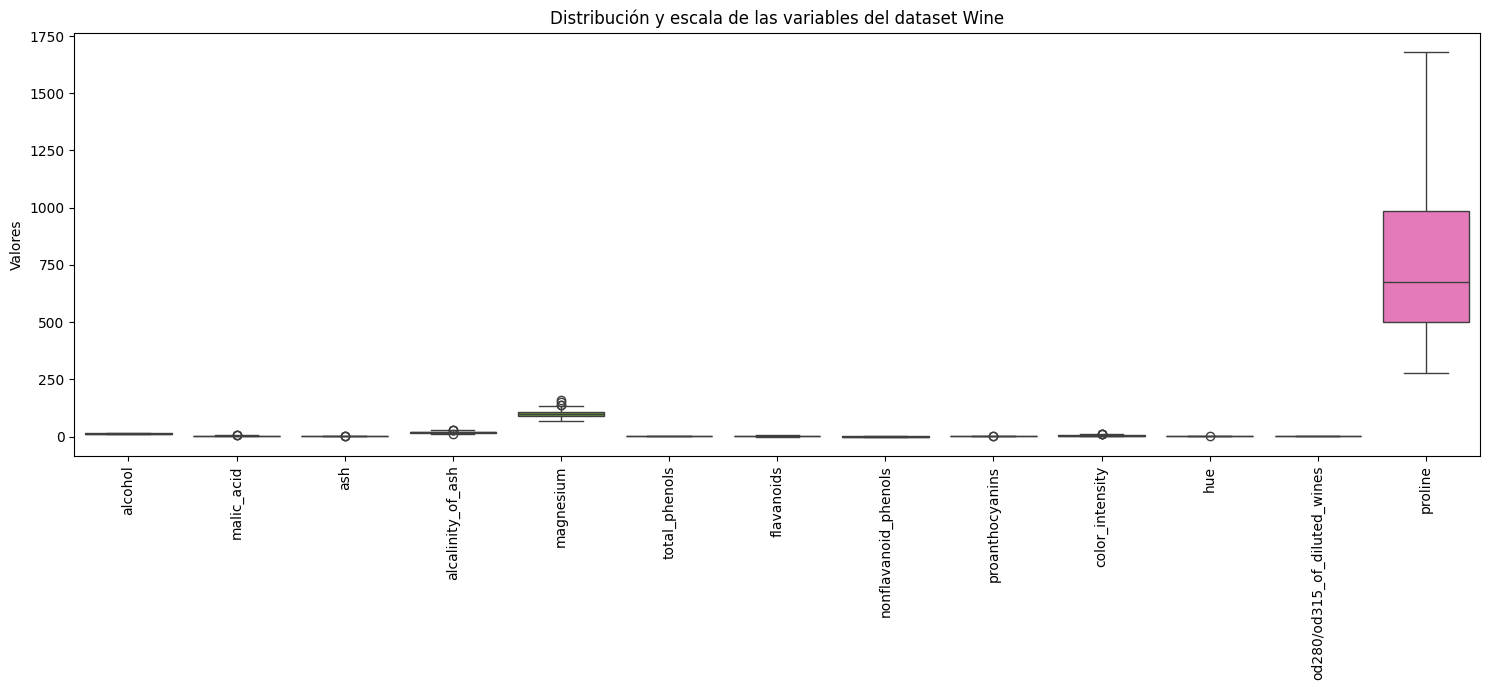

In [ ]:
# Visualizar las escalas mediante diagramas de caja
plt.figure(figsize=(15, 7))

sns.boxplot(data=X)

plt.title("Distribución y escala de las variables del dataset Wine")
plt.xticks(rotation=90)
plt.ylabel("Valores")
plt.tight_layout()
plt.show()

La gráfica permite observar que las variables presentan diferentes escalas y rangos de valores. Por esta razón, es necesario estandarizar los datos antes de aplicar K-Means, ya que el algoritmo utiliza distancias para formar los grupos y las variables con valores más grandes podrían tener mayor influencia.

In [ ]:
# Crear el objeto StandardScaler
scaler = StandardScaler()

# Estandarizar las variables predictoras
X_scaled = scaler.fit_transform(X)

# Convertir los datos estandarizados en DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Mostrar los primeros registros
X_scaled.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [ ]:
# Revisar medias y desviaciones estándar
print("Media de las variables estandarizadas:")
print(X_scaled.mean().round(2))

print("\nDesviación estándar:")
print(X_scaled.std().round(2))

Media de las variables estandarizadas:
alcohol                         0.0
malic_acid                      0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                -0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Desviación estándar:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline                 

Se aplicó el método StandardScaler para transformar las variables, de manera que tengan una media cercana a cero y una desviación estándar cercana a uno. Este procedimiento evita que las diferencias en las escalas afecten excesivamente la formación de los clusters.

In [ ]:
# ==========================================
# IMPLEMENTACIÓN DE K-MEANS
# ==========================================

# Valores de K que vamos a evaluar
valores_k = [2, 3, 4, 5, 6]

# Listas para almacenar los resultados
inercias = []
silhouette_scores = []

# Ejecutar K-Means para cada valor de K
for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = modelo.fit_predict(X_scaled)

    # Calcular inercia
    inercia = modelo.inertia_
    inercias.append(inercia)

    # Calcular Silhouette Score
    silhouette = silhouette_score(X_scaled, clusters)
    silhouette_scores.append(silhouette)

    print(f"K = {k}")
    print(f"Inercia: {inercia:.2f}")
    print(f"Silhouette Score: {silhouette:.4f}")
    print("-----------------------------")

K = 2
Inercia: 1658.76
Silhouette Score: 0.2593
-----------------------------
K = 3
Inercia: 1277.93
Silhouette Score: 0.2849
-----------------------------
K = 4
Inercia: 1175.43
Silhouette Score: 0.2602
-----------------------------
K = 5
Inercia: 1109.51
Silhouette Score: 0.2016
-----------------------------
K = 6
Inercia: 1046.00
Silhouette Score: 0.2372
-----------------------------


In [ ]:
# Crear tabla de resultados
resultados_kmeans = pd.DataFrame({
    "Número de clusters (K)": valores_k,
    "Inercia": inercias,
    "Silhouette Score": silhouette_scores
})

resultados_kmeans

,Número de clusters (K),Inercia,Silhouette Score
0,2,1658.758852,0.259317
1,3,1277.928489,0.284859
2,4,1175.428333,0.260170
3,5,1109.512739,0.201619
4,6,1046.002333,0.237167


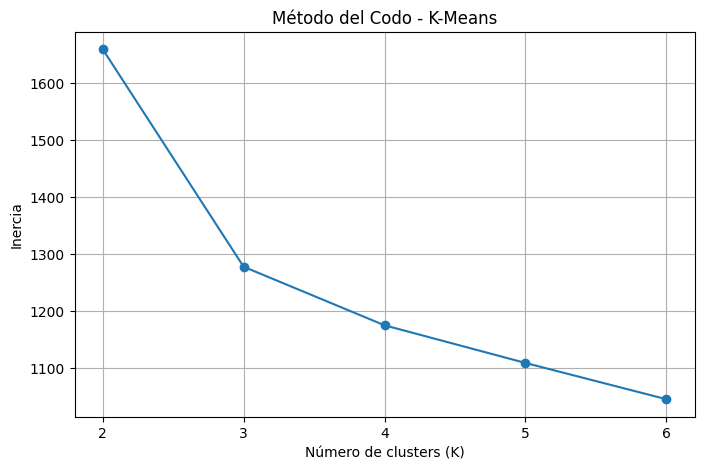

In [ ]:
# Gráfica del Método del Codo

plt.figure(figsize=(8, 5))

plt.plot(
    valores_k,
    inercias,
    marker='o',
    linestyle='-'
)

plt.title("Método del Codo - K-Means")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

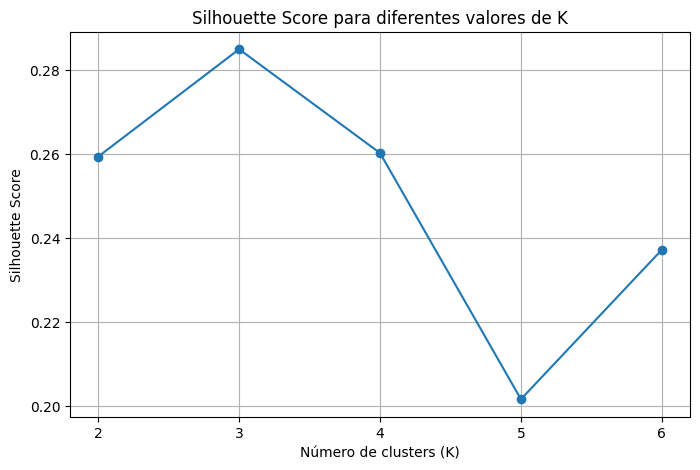

In [ ]:
# Gráfica del Silhouette Score

plt.figure(figsize=(8, 5))

plt.plot(
    valores_k,
    silhouette_scores,
    marker='o',
    linestyle='-'
)

plt.title("Silhouette Score para diferentes valores de K")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

In [ ]:
# Identificar el K con mayor Silhouette Score

mejor_indice = np.argmax(silhouette_scores)
mejor_k = valores_k[mejor_indice]

print("Mejor número de clusters según Silhouette Score:", mejor_k)
print("Silhouette Score:", round(silhouette_scores[mejor_indice], 4))

Mejor número de clusters según Silhouette Score: 3
Silhouette Score: 0.2849


In [ ]:
# Definir el número de clusters seleccionado
k_final = mejor_k

# Crear y entrenar el modelo definitivo
kmeans_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

# Obtener las etiquetas de los clusters
clusters_finales = kmeans_final.fit_predict(X_scaled)

# Agregar los clusters al dataset original
X_resultados = X.copy()
X_resultados["Cluster"] = clusters_finales

print("Modelo K-Means ejecutado correctamente.")
print("Número de clusters:", k_final)

X_resultados.head()

Modelo K-Means ejecutado correctamente.
Número de clusters: 3


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2


In [ ]:
# Calcular métricas del modelo definitivo

silhouette_final = silhouette_score(
    X_scaled,
    clusters_finales
)

davies_final = davies_bouldin_score(
    X_scaled,
    clusters_finales
)

calinski_final = calinski_harabasz_score(
    X_scaled,
    clusters_finales
)

print("RESULTADOS DEL MODELO DEFINITIVO")
print("--------------------------------")
print("Silhouette Score:", round(silhouette_final, 4))
print("Davies-Bouldin Index:", round(davies_final, 4))
print("Calinski-Harabasz Score:", round(calinski_final, 4))

RESULTADOS DEL MODELO DEFINITIVO
--------------------------------
Silhouette Score: 0.2849
Davies-Bouldin Index: 1.3892
Calinski-Harabasz Score: 70.94


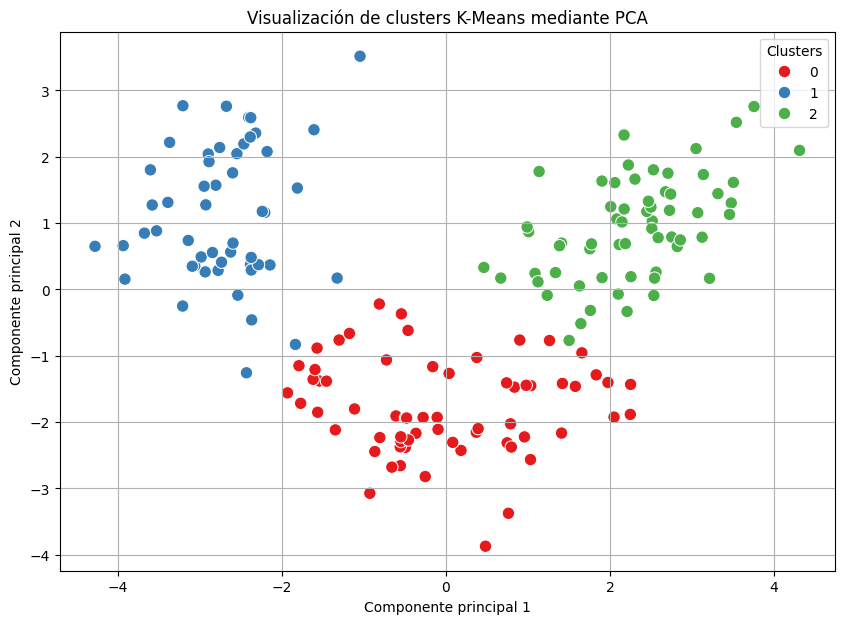

In [ ]:
# Aplicar PCA con dos componentes

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Crear DataFrame con los componentes
df_pca = pd.DataFrame(
    X_pca,
    columns=["Componente 1", "Componente 2"]
)

df_pca["Cluster"] = clusters_finales

# Visualizar clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_pca,
    x="Componente 1",
    y="Componente 2",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.title("Visualización de clusters K-Means mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Clusters")
plt.grid(True)
plt.show()

In [ ]:
# Calcular el promedio de las variables originales por cluster

perfil_clusters = X_resultados.groupby("Cluster").mean()

perfil_clusters.T

Cluster,0,1,2
alcohol,12.250923,13.134118,13.676774
malic_acid,1.897385,3.307255,1.997903
ash,2.231231,2.417647,2.466290
alcalinity_of_ash,20.063077,21.241176,17.462903
magnesium,92.738462,98.666667,107.967742
total_phenols,2.247692,1.683922,2.847581
flavanoids,2.050000,0.818824,3.003226
nonflavanoid_phenols,0.357692,0.451961,0.292097
proanthocyanins,1.624154,1.145882,1.922097
color_intensity,2.973077,7.234706,5.453548


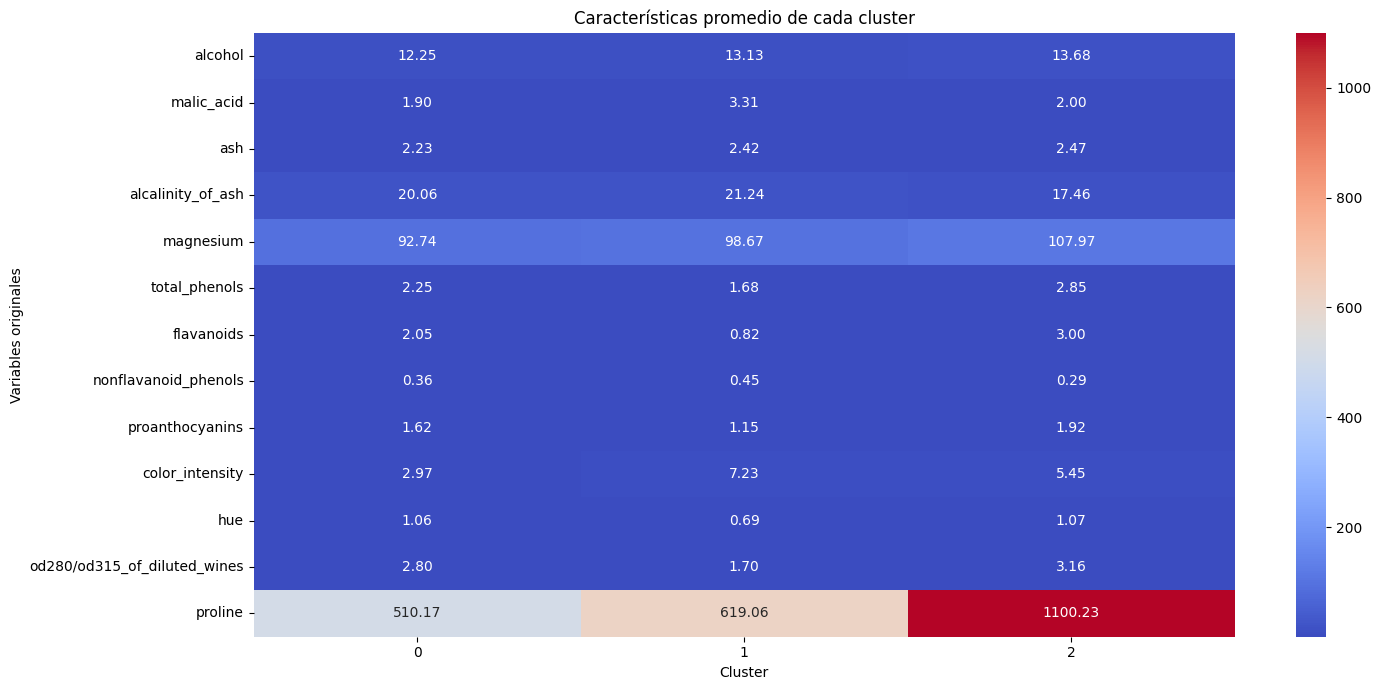

In [ ]:
# Gráfica de características por cluster

plt.figure(figsize=(15, 7))

sns.heatmap(
    perfil_clusters.T,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Características promedio de cada cluster")
plt.xlabel("Cluster")
plt.ylabel("Variables originales")
plt.tight_layout()
plt.show()

In [ ]:
# Seleccionar el número de clusters
k_final = 3

print("Número de clusters seleccionado:", k_final)

Número de clusters seleccionado: 3


In [ ]:
# Crear y entrenar el modelo K-Means definitivo
modelo_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

clusters_finales = modelo_final.fit_predict(X_scaled)

# Agregar los clusters al conjunto de datos original
X_resultados = X.copy()
X_resultados["Cluster"] = clusters_finales

X_resultados.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2


In [ ]:
# Calcular métricas de evaluación

silhouette_final = silhouette_score(X_scaled, clusters_finales)

davies_bouldin = davies_bouldin_score(X_scaled, clusters_finales)

calinski_harabasz = calinski_harabasz_score(X_scaled, clusters_finales)

print("RESULTADOS DEL MODELO K-MEANS")
print("--------------------------------")
print("Número de clusters:", k_final)
print("Silhouette Score:", silhouette_final)
print("Davies-Bouldin Index:", davies_bouldin)
print("Calinski-Harabasz Index:", calinski_harabasz)

RESULTADOS DEL MODELO K-MEANS
--------------------------------
Número de clusters: 3
Silhouette Score: 0.2848589191898987
Davies-Bouldin Index: 1.3891879777181646
Calinski-Harabasz Index: 70.9400080031512


El modelo K-Means, con tres clusters, obtuvo un Silhouette Score de 0.2849, lo que indica que la separación entre los grupos es limitada. El índice Davies-Bouldin fue de 1.3892, mientras que el índice Calinski-Harabasz alcanzó 70.94. En conjunto, estos resultados muestran que el modelo logra identificar tres agrupaciones dentro de los datos, aunque existen algunas similitudes entre sus integrantes.

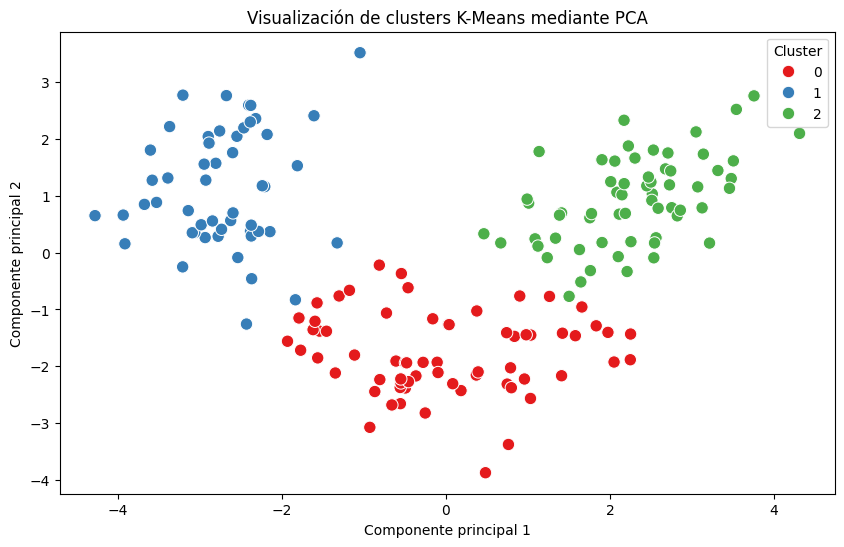

In [ ]:
# Aplicar PCA para reducir los datos a dos dimensiones
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Crear un DataFrame con los componentes principales
df_pca = pd.DataFrame(
    X_pca,
    columns=["Componente 1", "Componente 2"]
)

df_pca["Cluster"] = clusters_finales

# Graficar los clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_pca,
    x="Componente 1",
    y="Componente 2",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.title("Visualización de clusters K-Means mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Cluster")
plt.show()

In [ ]:
# Mostrar los primeros registros de la visualización
print(df_pca.head(10))

# Mostrar cuántas muestras hay en cada cluster
print("\nCantidad de muestras por cluster:")
print(df_pca["Cluster"].value_counts())

# Mostrar el porcentaje de varianza explicado
print("\nVarianza explicada por los componentes:")
print(pca.explained_variance_ratio_)

print(
    "\nVarianza total explicada:",
    pca.explained_variance_ratio_.sum() * 100,
    "%"
)

   Componente 1  Componente 2  Cluster
0      3.316751      1.443463        2
1      2.209465     -0.333393        2
2      2.516740      1.031151        2
3      3.757066      2.756372        2
4      1.008908      0.869831        2
5      3.050254      2.122401        2
6      2.449090      1.174850        2
7      2.059437      1.608963        2
8      2.510874      0.918071        2
9      2.753628      0.789438        2

Cantidad de muestras por cluster:
Cluster
0    65
2    62
1    51
Name: count, dtype: int64

Varianza explicada por los componentes:
[0.36198848 0.1920749 ]

Varianza total explicada: 55.40633835693526 %


In [ ]:
# Calcular el promedio de las variables originales por cluster
perfil_clusters = X_resultados.groupby("Cluster").mean()

# Mostrar los resultados
display(perfil_clusters.T)

Cluster,0,1,2
alcohol,12.250923,13.134118,13.676774
malic_acid,1.897385,3.307255,1.997903
ash,2.231231,2.417647,2.466290
alcalinity_of_ash,20.063077,21.241176,17.462903
magnesium,92.738462,98.666667,107.967742
total_phenols,2.247692,1.683922,2.847581
flavanoids,2.050000,0.818824,3.003226
nonflavanoid_phenols,0.357692,0.451961,0.292097
proanthocyanins,1.624154,1.145882,1.922097
color_intensity,2.973077,7.234706,5.453548


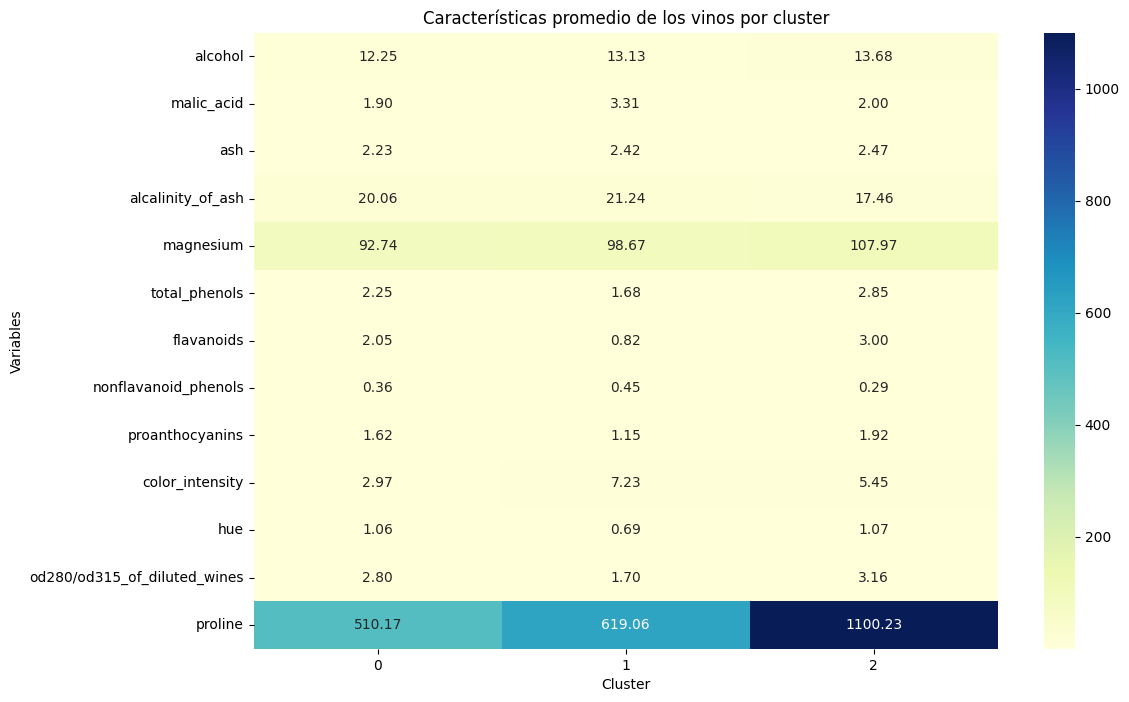

In [ ]:
# Crear un mapa de calor de las características por cluster
plt.figure(figsize=(12, 8))

sns.heatmap(
    perfil_clusters.T,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Características promedio de los vinos por cluster")
plt.xlabel("Cluster")
plt.ylabel("Variables")
plt.show()

In [ ]:
# Mostrar la tabla completa en formato de texto
print(perfil_clusters.T.to_string())

Cluster                                0           1            2
alcohol                        12.250923   13.134118    13.676774
malic_acid                      1.897385    3.307255     1.997903
ash                             2.231231    2.417647     2.466290
alcalinity_of_ash              20.063077   21.241176    17.462903
magnesium                      92.738462   98.666667   107.967742
total_phenols                   2.247692    1.683922     2.847581
flavanoids                      2.050000    0.818824     3.003226
nonflavanoid_phenols            0.357692    0.451961     0.292097
proanthocyanins                 1.624154    1.145882     1.922097
color_intensity                 2.973077    7.234706     5.453548
hue                             1.062708    0.691961     1.065484
od280/od315_of_diluted_wines    2.803385    1.696667     3.163387
proline                       510.169231  619.058824  1100.225806


**Análisis de los clusters**

Cluster 0 (65 muestras):

Presenta un contenido promedio de alcohol de 12.25 y una intensidad de color de 2.97. Tiene valores intermedios de fenoles y flavonoides. Su concentración promedio de prolina es de 510.17, la más baja de los tres grupos.

Cluster 1 (51 muestras):

Se caracteriza por tener el mayor contenido de ácido málico (3.31), la menor concentración de fenoles totales (1.68) y flavonoides (0.82). También presenta la mayor intensidad de color (7.23) y el menor valor de tonalidad (0.69).

Cluster 2 (62 muestras):

Presenta el mayor contenido promedio de alcohol (13.68), magnesio (107.97), fenoles totales (2.85), flavonoides (3.00) y prolina (1100.23). Se diferencia por sus valores elevados en varias de estas características.

**Conclusión**

La caracterización de los clusters permitió identificar diferencias en las propiedades físico-químicas de las muestras de vino. El cluster 0 presenta los valores más bajos de prolina y una intensidad de color reducida. El cluster 1 se distingue por su mayor contenido de ácido málico e intensidad de color, junto con menores concentraciones de fenoles y flavonoides. Por su parte, el cluster 2 registra los valores más altos de alcohol, magnesio, fenoles, flavonoides y prolina. Estos resultados muestran que K-Means logró agrupar las muestras según similitudes en sus características.

# **Ejercicio 1:**

1. ¿Por qué es necesario estandarizar los datos antes de aplicar K-Means?

Es necesario porque las variables tienen diferentes escalas y unidades de medida. La estandarización permite que todas tengan una influencia comparable en el cálculo de las distancias, evitando que las variables con valores más grandes dominen la agrupación.

2. ¿Qué representa el método del codo?

Representa la relación entre el número de clusters y la inercia. Permite identificar un punto en el que aumentar la cantidad de grupos deja de producir una reducción importante de la inercia.

3. ¿Qué indica el Silhouette Score obtenido?

El valor de 0.2849 indica que existe cierta separación entre los clusters, aunque también hay similitudes entre algunas muestras de diferentes grupos.

4. ¿Los clusters representan las clases originales del dataset Wine?

No necesariamente. Los clusters se construyeron utilizando las características físico-químicas, sin utilizar las clases originales. Por eso, los grupos encontrados no tienen que coincidir exactamente con las categorías del dataset.

5. ¿Qué ventajas y limitaciones presenta K-Means?

Su ventaja principal es que permite agrupar datos de manera sencilla y eficiente. Entre sus limitaciones están la necesidad de definir previamente el número de clusters y su sensibilidad a las escalas de las variables y a los valores atípicos.

# **EJERCICIO 2. DBSCAN – AGRUPAMIENTO BASADO EN DENSIDAD Y DETECCIÓN DE RUIDO**

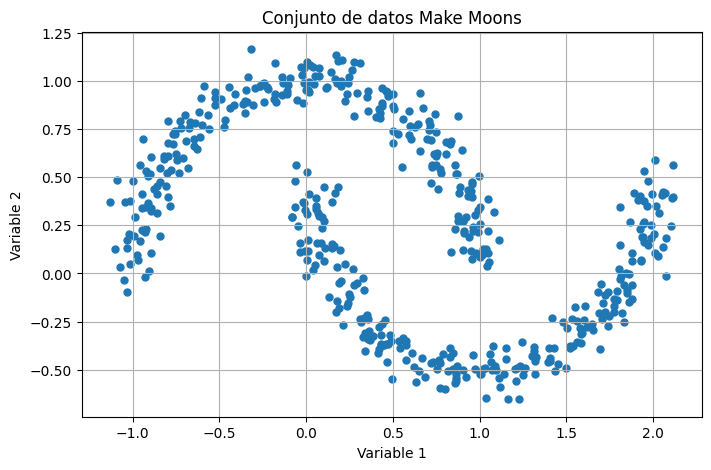

Número de observaciones: 500
Número de variables: 2


In [1]:

# Importar las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Generar el conjunto de datos
X, y = make_moons(
    n_samples=500,
    noise=0.07,
    random_state=42
)

# Visualizar los datos originales
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=25)
plt.title("Conjunto de datos Make Moons")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.grid(True)
plt.show()

# Mostrar las dimensiones del conjunto de datos
print("Número de observaciones:", X.shape[0])
print("Número de variables:", X.shape[1])


El conjunto de datos presenta una estructura formada por dos grupos de observaciones con una distribución curva, similar a dos medias lunas entrelazadas. Esta forma permite analizar la capacidad de DBSCAN para identificar agrupaciones con estructuras no lineales y diferentes densidades, sin necesidad de definir previamente el número de clusters.

In [2]:

# Importar StandardScaler
from sklearn.preprocessing import StandardScaler

# Estandarizar las variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Mostrar los primeros cinco registros
print("Primeros cinco registros estandarizados:")
print(X_scaled[:5])

# Verificar las medias y desviaciones estándar
print("\nMedia de las variables:")
print(X_scaled.mean(axis=0))

print("\nDesviación estándar de las variables:")
print(X_scaled.std(axis=0))


Primeros cinco registros estandarizados:
[[ 0.3723429  -1.36514286]
 [ 0.26868736  1.14341769]
 [ 0.6052224  -1.47881003]
 [-0.9182133   1.42037934]
 [-0.22751598  1.67824956]]

Media de las variables:
[-3.77475828e-18 -2.78443935e-16]

Desviación estándar de las variables:
[1. 1.]


La estandarización permite que las dos variables tengan una escala comparable, con una media cercana a cero y una desviación estándar cercana a uno. Esto evita que las diferencias de escala afecten el cálculo de distancias utilizado por DBSCAN.

In [3]:

# Importar el algoritmo DBSCAN
from sklearn.cluster import DBSCAN

# Implementar DBSCAN con una configuración inicial
dbscan = DBSCAN(eps=0.2, min_samples=5)

# Ajustar el modelo y obtener las etiquetas
labels = dbscan.fit_predict(X_scaled)

# Identificar los clusters y los puntos de ruido
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("Número de clusters encontrados:", n_clusters)
print("Número de puntos clasificados como ruido:", n_noise)


Número de clusters encontrados: 2
Número de puntos clasificados como ruido: 4


Se implementó el algoritmo DBSCAN utilizando los parámetros iniciales eps=0.2 y min_samples=5. El parámetro eps establece la distancia máxima entre dos observaciones para considerarlas vecinas, mientras que min_samples determina la cantidad mínima de puntos necesaria para formar una región de alta densidad.

In [4]:

# Definir diferentes configuraciones
configuraciones = [
    (0.1, 5),
    (0.2, 5),
    (0.3, 5),
    (0.2, 10)
]

# Evaluar cada configuración
resultados = []

for eps, min_samples in configuraciones:
    modelo = DBSCAN(eps=eps, min_samples=min_samples)
    etiquetas = modelo.fit_predict(X_scaled)

    n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    n_ruido = np.sum(etiquetas == -1)
    porcentaje_ruido = (n_ruido / len(X_scaled)) * 100

    resultados.append({
        "eps": eps,
        "min_samples": min_samples,
        "Clusters": n_clusters,
        "Puntos de ruido": n_ruido,
        "Ruido (%)": round(porcentaje_ruido, 2)
    })

# Mostrar resultados en una tabla
import pandas as pd

tabla_resultados = pd.DataFrame(resultados)
print(tabla_resultados.to_string(index=False))


 eps  min_samples  Clusters  Puntos de ruido  Ruido (%)
 0.1            5        24              118       23.6
 0.2            5         2                4        0.8
 0.3            5         2                0        0.0
 0.2           10         2                8        1.6


Al comparar las diferentes configuraciones se observa que el valor de eps influye directamente en la cantidad de clusters y puntos clasificados como ruido. Con eps = 0.1 se obtuvieron 24 clusters y 118 puntos de ruido, lo que indica que la distancia establecida fue demasiado pequeña para identificar adecuadamente los grupos.

Con eps = 0.2 se encontraron dos clusters y solamente cuatro puntos de ruido. Al aumentar eps a 0.3 se mantuvieron los dos clusters, pero desaparecieron los puntos clasificados como ruido. Por otra parte, al aumentar min_samples a 10, manteniendo eps = 0.2, se conservaron los dos clusters y aumentó ligeramente la cantidad de puntos de ruido.

**eps = 0.2 y min_samples = 5**

Se seleccionó esta configuración porque permitió identificar los dos grupos principales presentes en el conjunto de datos, clasificando únicamente cuatro observaciones como ruido, equivalentes al 0.8 %. Este resultado representa un equilibrio adecuado entre la identificación de las agrupaciones y la detección de observaciones aisladas, sin generar una cantidad excesiva de clusters ni incorporar todos los puntos a los grupos.

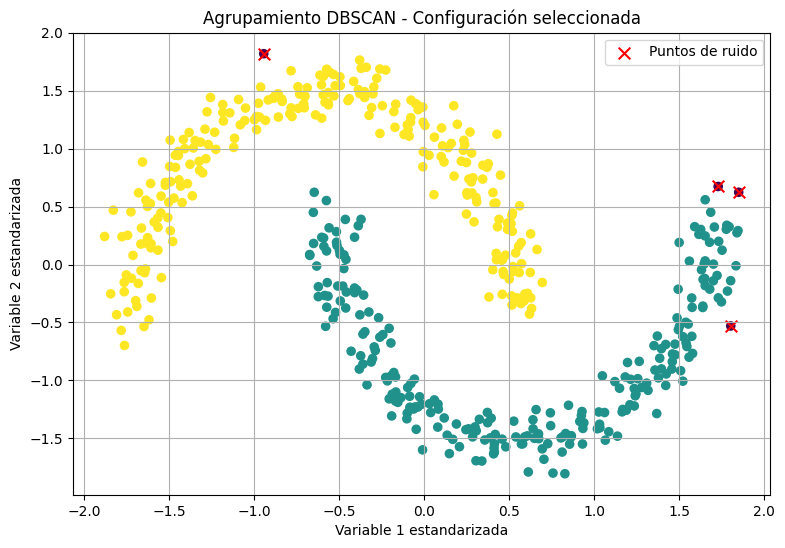

In [5]:

# Aplicar DBSCAN con la configuración seleccionada
dbscan_final = DBSCAN(eps=0.2, min_samples=5)
labels_final = dbscan_final.fit_predict(X_scaled)

# Representar los clusters y puntos de ruido
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_final,
    cmap='viridis',
    s=35
)

# Resaltar los puntos de ruido
ruido = labels_final == -1

plt.scatter(
    X_scaled[ruido, 0],
    X_scaled[ruido, 1],
    color='red',
    marker='x',
    s=70,
    label='Puntos de ruido'
)

plt.title('Agrupamiento DBSCAN - Configuración seleccionada')
plt.xlabel('Variable 1 estandarizada')
plt.ylabel('Variable 2 estandarizada')
plt.legend()
plt.grid(True)
plt.show()


**Análisis del tratamiento del ruido:**

Para calcular las métricas de evaluación se excluyeron los cuatro puntos identificados como ruido por DBSCAN, representados con la etiqueta -1. Esto se realizó porque dichas observaciones no pertenecen a ningún cluster y su inclusión podría distorsionar la evaluación de la separación y cohesión de los grupos. Por esta razón, las métricas se calcularon únicamente con las observaciones asignadas a los dos clusters identificados.

In [6]:

# Importar métricas de evaluación
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Excluir los puntos clasificados como ruido (-1)
mascara = labels_final != -1

X_sin_ruido = X_scaled[mascara]
labels_sin_ruido = labels_final[mascara]

# Calcular las métricas
if len(set(labels_sin_ruido)) >= 2:
    silhouette = silhouette_score(X_sin_ruido, labels_sin_ruido)
    davies = davies_bouldin_score(X_sin_ruido, labels_sin_ruido)
    calinski = calinski_harabasz_score(X_sin_ruido, labels_sin_ruido)

    print("Silhouette Score:", round(silhouette, 4))
    print("Davies-Bouldin Index:", round(davies, 4))
    print("Calinski-Harabasz Score:", round(calinski, 4))
else:
    print("No hay suficientes clusters para calcular las métricas.")

print("Observaciones utilizadas:", len(X_sin_ruido))
print("Observaciones excluidas por ruido:", np.sum(~mascara))


Silhouette Score: 0.3869
Davies-Bouldin Index: 1.0179
Calinski-Harabasz Score: 433.6268
Observaciones utilizadas: 496
Observaciones excluidas por ruido: 4


La evaluación del algoritmo DBSCAN presentó un Silhouette Score de 0.3869, lo que indica una separación moderada entre los dos clusters identificados. El índice Davies-Bouldin obtuvo un valor de 1.0179, mostrando una relación aceptable entre la dispersión interna y la separación de los grupos. Por su parte, el índice Calinski-Harabasz registró un valor de 433.6268, lo que refleja una separación entre grupos en relación con su dispersión interna.

Las métricas se calcularon utilizando 496 observaciones, excluyendo los cuatro puntos clasificados como ruido. En general, los resultados muestran que DBSCAN logró identificar adecuadamente las dos agrupaciones principales del conjunto de datos.

# **Ejercicio 2**

1. ¿Qué ocurre cuando se disminuye demasiado eps?

Cuando eps disminuye demasiado, el radio de búsqueda de vecinos se reduce y el algoritmo encuentra menos puntos cercanos entre sí. Esto puede provocar que los grupos se dividan en muchos clusters pequeños y que aumente considerablemente la cantidad de puntos clasificados como ruido.

2. ¿Qué ocurre cuando eps aumenta?

Cuando eps aumenta, el radio de búsqueda se amplía y más observaciones pueden conectarse entre sí. Esto puede facilitar la formación de clusters, pero si el valor es demasiado alto, grupos diferentes pueden terminar unidos y disminuir la detección de puntos de ruido.

3. ¿Qué función cumple min_samples?

Este parámetro establece el número mínimo de observaciones necesarias dentro del radio eps para considerar que existe una región de alta densidad. Al aumentar su valor, el algoritmo exige mayor concentración de puntos para formar clusters.

4. ¿Qué representan los puntos identificados como ruido?

Representan las observaciones que no cumplen las condiciones de densidad necesarias para pertenecer a un cluster. En este ejercicio se identificaron cuatro puntos como ruido, equivalentes al 0.8 % del conjunto de datos.

5. ¿Qué configuración produjo el resultado más coherente?

La configuración eps = 0.2 y min_samples = 5 produjo el resultado más coherente, ya que identificó los dos grupos principales y clasificó solamente cuatro observaciones como ruido. Además, permitió obtener métricas de evaluación que muestran una separación moderada entre los clusters.

6. ¿Por qué DBSCAN puede encontrar estructuras que podrían resultar difíciles para K-Means?

Porque DBSCAN agrupa las observaciones según su densidad y no según la distancia a un centroide. Esto le permite identificar grupos con formas irregulares o curvas, como las dos medias lunas del conjunto de datos, que pueden ser difíciles de identificar correctamente mediante K-Means.

7. ¿Qué ventajas y limitaciones observa en este algoritmo?

Una de sus principales ventajas es que permite identificar clusters con formas diferentes y detectar puntos de ruido sin necesidad de establecer previamente el número de grupos. Entre sus limitaciones se encuentran la sensibilidad a los valores de eps y min_samples, y la dificultad para trabajar con conjuntos de datos que presentan densidades muy diferentes.

# **EJERCICIO 3. CLUSTERING JERÁRQUICO**

In [7]:

# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

# Cargar el conjunto de datos Iris
iris = load_iris()

# Trabajar únicamente con las variables predictoras
X_iris = iris.data

# Crear un DataFrame para visualizar los datos
df_iris = pd.DataFrame(
    X_iris,
    columns=iris.feature_names
)

# Mostrar información general
print("Número de registros:", X_iris.shape[0])
print("Número de variables:", X_iris.shape[1])

print("\nPrimeras cinco observaciones:")
print(df_iris.head())

print("\nInformación estadística:")
print(df_iris.describe())


Número de registros: 150
Número de variables: 4

Primeras cinco observaciones:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Información estadística:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000       

El conjunto de datos Iris contiene 150 observaciones y cuatro variables relacionadas con las características de las flores: longitud del sépalo, ancho del sépalo, longitud del pétalo y ancho del pétalo. Estas variables permiten analizar las similitudes entre las observaciones y construir agrupaciones mediante clustering jerárquico.

Para este ejercicio se utilizaron únicamente las cuatro variables numéricas, sin emplear las etiquetas de las especies en la construcción de los clusters.

In [9]:

# Importar StandardScaler
from sklearn.preprocessing import StandardScaler

# Crear el objeto de estandarización
scaler_iris = StandardScaler()

# Estandarizar las variables
X_iris_scaled = scaler_iris.fit_transform(X_iris)

# Verificar los resultados
print("Media de las variables:")
print(X_iris_scaled.mean(axis=0))

print("\nDesviación estándar:")
print(X_iris_scaled.std(axis=0))


Media de las variables:
[-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]

Desviación estándar:
[1. 1. 1. 1.]


Se estandarizaron las cuatro variables mediante StandardScaler para que todas tuvieran una escala comparable. Este procedimiento evita que las variables con valores numéricos mayores tengan una influencia desproporcionada en el cálculo de las distancias utilizadas para construir los grupos.

In [10]:
X_iris = iris.data

El conjunto de datos Iris está compuesto por 150 registros y cuatro variables numéricas. Al revisar las estadísticas descriptivas se observa que las variables presentan diferentes escalas y rangos de valores, por lo que fue necesario aplicar la estandarización.

Después de utilizar StandardScaler, las medias de las variables quedaron aproximadamente en cero y sus desviaciones estándar en uno. Esto permite trabajar con las cuatro características en condiciones comparables para aplicar el clustering jerárquico.

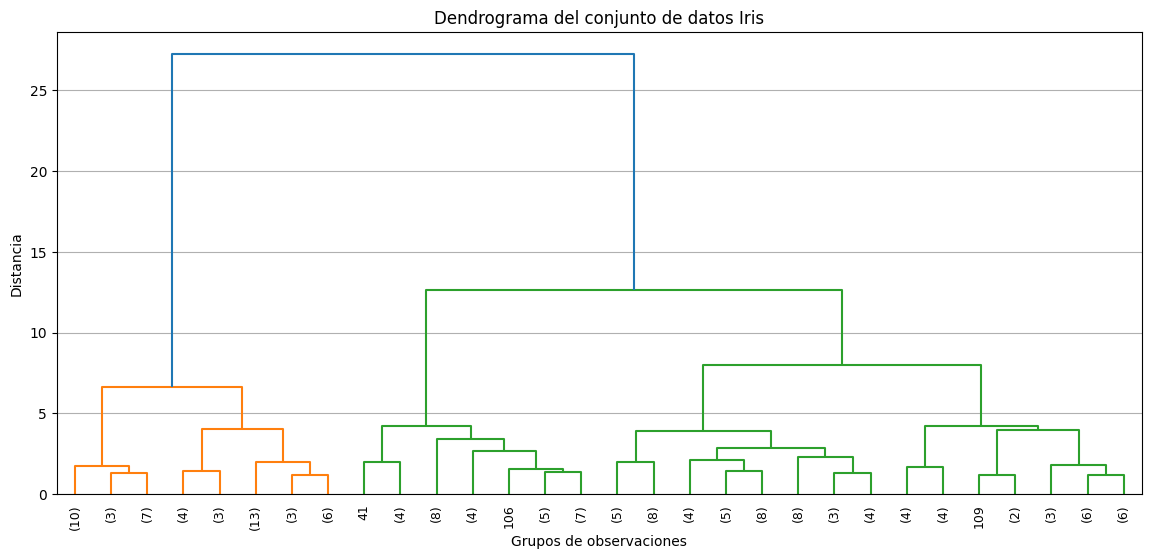

In [11]:

# Importar las funciones necesarias
from scipy.cluster.hierarchy import dendrogram, linkage

# Construir la matriz de enlace
Z = linkage(X_iris_scaled, method='ward')

# Representar el dendrograma
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Dendrograma del conjunto de datos Iris")
plt.xlabel("Grupos de observaciones")
plt.ylabel("Distancia")
plt.grid(axis='y')
plt.show()


Se construyó un dendrograma utilizando el método de Ward, que agrupa progresivamente las observaciones buscando minimizar el aumento de la variabilidad interna de los grupos. La representación permite observar cómo se van uniendo las agrupaciones y las distancias a las que se producen estas uniones.

El dendrograma muestra cómo las observaciones se agrupan progresivamente según sus distancias. Las uniones que se producen a distancias pequeñas representan observaciones o grupos con características similares, mientras que las uniones a distancias mayores indican agrupaciones más diferentes. Los saltos grandes en las distancias permiten identificar posibles puntos de corte para determinar el número de clusters.

In [12]:

# Mostrar las últimas distancias de unión del dendrograma
print("Últimas 15 distancias de unión:")
print(Z[-15:, 2])


Últimas 15 distancias de unión:
[ 2.01781256  2.14172453  2.3033894   2.69536867  2.86888385  3.44191215
  3.93266869  3.95076988  4.06134011  4.22703313  4.24348495  6.60781224
  8.00474726 12.63684352 27.24991146]


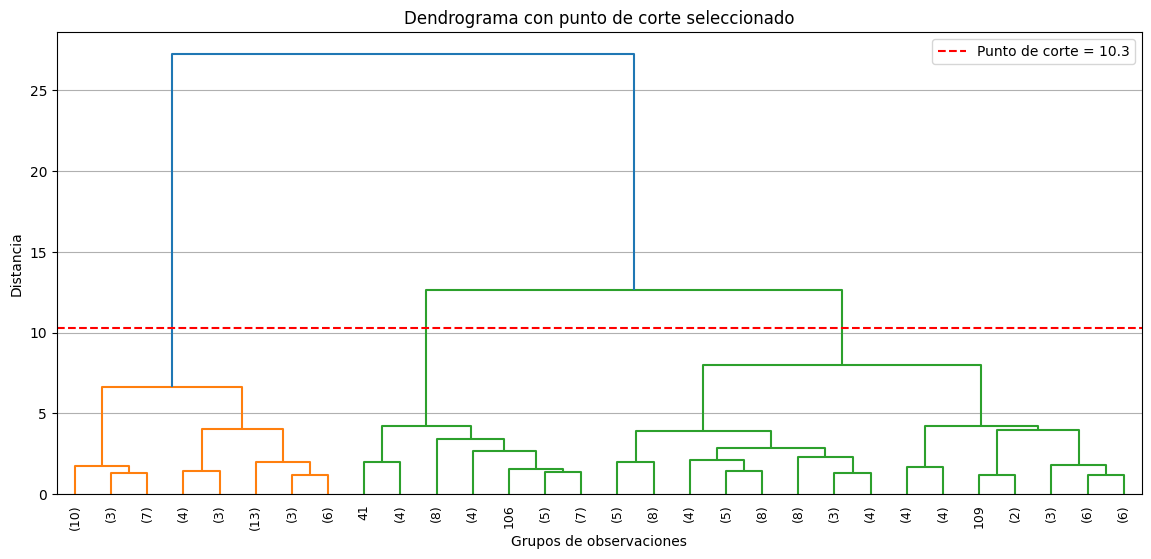

In [13]:

# Representar el dendrograma con el punto de corte seleccionado
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.axhline(
    y=10.3,
    color='red',
    linestyle='--',
    label='Punto de corte = 10.3'
)

plt.title("Dendrograma con punto de corte seleccionado")
plt.xlabel("Grupos de observaciones")
plt.ylabel("Distancia")
plt.legend()
plt.grid(axis='y')
plt.show()


Se seleccionó un punto de corte aproximado de 10.3, teniendo en cuenta los saltos observados en las últimas distancias de unión del dendrograma. Esta decisión permite identificar tres clusters, evitando unir grupos que presentan diferencias importantes. Se considera una alternativa adecuada para analizar la estructura del conjunto de datos Iris.

In [14]:

# Implementar clustering jerárquico con 3 clusters
from sklearn.cluster import AgglomerativeClustering

modelo_jerarquico = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

# Obtener las etiquetas de los clusters
labels_jerarquico = modelo_jerarquico.fit_predict(
    X_iris_scaled
)

# Mostrar la distribución de los clusters
print("Distribución de los clusters:")
print(
    pd.Series(labels_jerarquico)
    .value_counts()
    .sort_index()
)


Distribución de los clusters:
0    71
1    49
2    30
Name: count, dtype: int64


El algoritmo Agglomerative Clustering, utilizando el método Ward y estableciendo tres clusters, agrupó las 150 observaciones en tres conjuntos. El primer cluster contiene 71 observaciones, el segundo 49 y el tercero 30. Esta distribución evidencia que el algoritmo identificó agrupaciones de diferentes tamaños según las similitudes entre las características de las flores.

In [15]:

# Importar las métricas de evaluación
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Calcular las métricas
silhouette_jerarquico = silhouette_score(
    X_iris_scaled, labels_jerarquico
)

davies_jerarquico = davies_bouldin_score(
    X_iris_scaled, labels_jerarquico
)

calinski_jerarquico = calinski_harabasz_score(
    X_iris_scaled, labels_jerarquico
)

# Mostrar los resultados
print("Silhouette Score:",
      round(silhouette_jerarquico, 4))

print("Davies-Bouldin Index:",
      round(davies_jerarquico, 4))

print("Calinski-Harabasz Score:",
      round(calinski_jerarquico, 4))


Silhouette Score: 0.4467
Davies-Bouldin Index: 0.8035
Calinski-Harabasz Score: 222.7192


El algoritmo de clustering jerárquico obtuvo un Silhouette Score de 0.4467, lo que indica una separación moderada entre los grupos. El índice Davies-Bouldin presentó un valor de 0.8035, mostrando una relación favorable entre la dispersión interna y la separación de los clusters. Por su parte, el índice Calinski-Harabasz obtuvo un resultado de 222.7192, que permite evaluar la separación de los grupos en relación con su dispersión interna.

En general, los resultados muestran que el algoritmo logró identificar tres agrupaciones con una separación razonable, aunque todavía existen algunas similitudes entre las observaciones de diferentes clusters.

In [16]:

# Importar PCA
from sklearn.decomposition import PCA

# Aplicar PCA con dos componentes
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_iris_scaled)

# Mostrar la varianza explicada
print("Varianza explicada por cada componente:")
print(pca.explained_variance_ratio_)

print("\nVarianza explicada acumulada:")
print(round(sum(pca.explained_variance_ratio_), 4))


Varianza explicada por cada componente:
[0.72962445 0.22850762]

Varianza explicada acumulada:
0.9581


Se aplicó PCA (Análisis de Componentes Principales) para reducir las cuatro variables originales a dos componentes principales. Este procedimiento permite representar gráficamente los clusters en un plano de dos dimensiones, conservando la mayor cantidad posible de información de los datos originales.

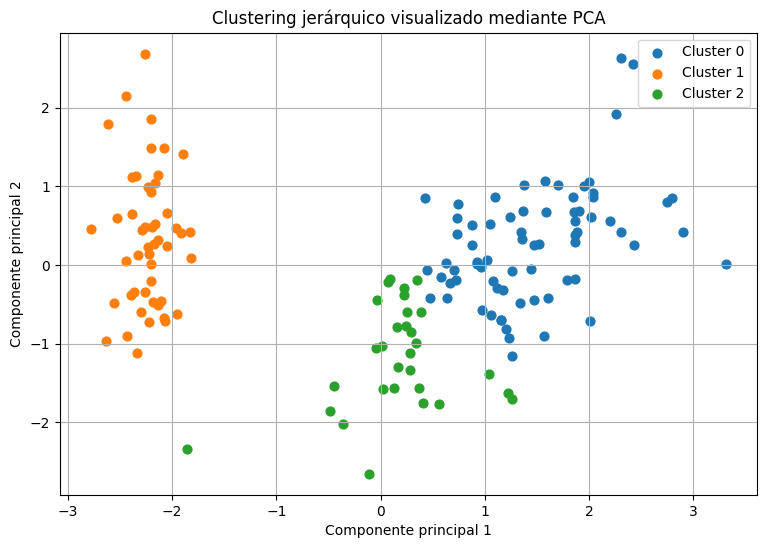

In [17]:

# Crear la gráfica de los clusters
plt.figure(figsize=(9, 6))

for cluster in np.unique(labels_jerarquico):
    plt.scatter(
        X_pca[labels_jerarquico == cluster, 0],
        X_pca[labels_jerarquico == cluster, 1],
        label=f'Cluster {cluster}',
        s=40
    )

plt.title("Clustering jerárquico visualizado mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.grid(True)
plt.show()


La representación mediante PCA permite observar la distribución de los tres clusters identificados por el algoritmo jerárquico. La gráfica facilita analizar visualmente la separación y las posibles similitudes entre los grupos, utilizando dos componentes principales que resumen parte de la información de las cuatro variables originales.

**Análisis de la reducción de dimensionalidad:**

Al aplicar PCA se obtuvo que el primer componente principal explica el 72.96 % de la variabilidad de los datos, mientras que el segundo componente explica el 22.85 %. En conjunto, ambos componentes representan el 95.81 % de la información original del conjunto de datos.

Esto indica que la reducción de cuatro variables a dos componentes permite conservar una proporción alta de la información, facilitando la visualización de los tres clusters identificados mediante el algoritmo jerárquico.

# **Ejercicio 3**

1. ¿Qué información proporciona el dendrograma?

El dendrograma representa gráficamente cómo se van agrupando las observaciones según sus distancias y similitudes. Permite identificar las relaciones entre los grupos y determinar un posible número de clusters mediante la selección de un punto de corte.

2. ¿En qué punto realizaría el corte?

Realizaría el corte aproximadamente en una distancia de 10.3, teniendo en cuenta los saltos observados en las últimas distancias de unión del dendrograma. Este punto permite identificar tres agrupaciones.

3. ¿Cuántos clusters propone y por qué?

Propongo tres clusters porque permiten organizar las 150 observaciones en grupos con características similares. La distribución obtenida fue de 71, 49 y 30 observaciones, respectivamente.

4. ¿Qué tan separados se encuentran los grupos?

Los grupos presentan una separación moderada, según el Silhouette Score de 0.4467. El índice Davies-Bouldin de 0.8035 también muestra una relación favorable entre la dispersión interna y la separación de los grupos, aunque todavía existen algunas similitudes entre observaciones de diferentes clusters.

5. ¿Qué diferencias encuentra entre este procedimiento y K-Means?

K-Means agrupa los datos alrededor de centroides y requiere establecer previamente el número de clusters. En cambio, el clustering jerárquico construye agrupaciones progresivas mediante las distancias entre observaciones y permite representar el proceso mediante un dendrograma.

6. ¿Qué ventajas ofrece una representación jerárquica?

Permite visualizar cómo se relacionan las observaciones y cómo se forman los grupos en diferentes niveles de distancia. Además, facilita explorar diferentes cantidades de clusters mediante la selección de distintos puntos de corte en el dendrograma.

# **Comparación de los algoritmos K-Means, DBSCAN y Clustering Jerárquico**

In [18]:

# Crear tabla comparativa de los tres algoritmos

comparacion = pd.DataFrame({
    "Aspecto": [
        "Forma de construir los grupos",
        "Número de clusters obtenidos",
        "Hiperparámetros principales",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score",
        "Identifica ruido",
        "Requiere definir previamente el número de clusters",
        "Principal ventaja",
        "Principal limitación"
    ],
    "K-Means": [
        "Agrupa según la distancia a los centroides",
        "3",
        "Número de clusters (K)",
        "0.2849",
        "No registrado",
        "No registrado",
        "No",
        "Sí",
        "Sencillo y eficiente",
        "Sensible a valores atípicos y formas de los grupos"
    ],
    "DBSCAN": [
        "Agrupa según la densidad de las observaciones",
        "2",
        "eps=0.2, min_samples=5",
        "0.3869",
        "1.0179",
        "433.6268",
        "Sí",
        "No",
        "Identifica grupos irregulares y ruido",
        "Sensible a los parámetros y a las densidades"
    ],
    "Clustering Jerárquico": [
        "Agrupa progresivamente según las distancias",
        "3",
        "Método Ward, 3 clusters",
        "0.4467",
        "0.8035",
        "222.7192",
        "No",
        "No necesariamente",
        "Permite visualizar las agrupaciones mediante dendrogramas",
        "Puede ser costoso con grandes volúmenes de datos"
    ]
})

display(comparacion)


,Aspecto,K-Means,DBSCAN,Clustering Jerárquico
0,Forma de construir los grupos,Agrupa según la distancia a los centroides,Agrupa según la densidad de las observaciones,Agrupa progresivamente según las distancias
1,Número de clusters obtenidos,3,2,3
2,Hiperparámetros principales,Número de clusters (K),"eps=0.2, min_samples=5","Método Ward, 3 clusters"
3,Silhouette Score,0.2849,0.3869,0.4467
4,Davies-Bouldin Index,No registrado,1.0179,0.8035
5,Calinski-Harabasz Score,No registrado,433.6268,222.7192
6,Identifica ruido,No,Sí,No
7,Requiere definir previamente el número de clus...,Sí,No,No necesariamente
8,Principal ventaja,Sencillo y eficiente,Identifica grupos irregulares y ruido,Permite visualizar las agrupaciones mediante d...
9,Principal limitación,Sensible a valores atípicos y formas de los gr...,Sensible a los parámetros y a las densidades,Puede ser costoso con grandes volúmenes de datos


Interpretación de la comparación
Agrega esta explicación en una celda de texto:

Al comparar los tres algoritmos se observa que cada uno utiliza un procedimiento diferente para identificar agrupaciones. K-Means organiza los datos alrededor de centroides, DBSCAN identifica grupos según la densidad de las observaciones y el clustering jerárquico construye agrupaciones progresivas mediante las distancias.

En los resultados obtenidos, el clustering jerárquico presentó el mayor Silhouette Score, con 0.4467, mientras que DBSCAN obtuvo 0.3869 y K-Means 0.2849. Esto indica que, dentro de cada ejercicio, el clustering jerárquico presentó una separación relativamente mejor entre sus grupos. Sin embargo, los tres algoritmos se aplicaron sobre conjuntos de datos diferentes, por lo que estos valores no permiten establecer una comparación directa de rendimiento entre ellos.

In [19]:
comparacion.loc[comparacion["Aspecto"] == "Davies-Bouldin Index", "K-Means"] = "1.3892"

comparacion.loc[comparacion["Aspecto"] == "Calinski-Harabasz Score", "K-Means"] = "70.9400"

display(comparacion)

,Aspecto,K-Means,DBSCAN,Clustering Jerárquico
0,Forma de construir los grupos,Agrupa según la distancia a los centroides,Agrupa según la densidad de las observaciones,Agrupa progresivamente según las distancias
1,Número de clusters obtenidos,3,2,3
2,Hiperparámetros principales,Número de clusters (K),"eps=0.2, min_samples=5","Método Ward, 3 clusters"
3,Silhouette Score,0.2849,0.3869,0.4467
4,Davies-Bouldin Index,1.3892,1.0179,0.8035
5,Calinski-Harabasz Score,70.9400,433.6268,222.7192
6,Identifica ruido,No,Sí,No
7,Requiere definir previamente el número de clus...,Sí,No,No necesariamente
8,Principal ventaja,Sencillo y eficiente,Identifica grupos irregulares y ruido,Permite visualizar las agrupaciones mediante d...
9,Principal limitación,Sensible a valores atípicos y formas de los gr...,Sensible a los parámetros y a las densidades,Puede ser costoso con grandes volúmenes de datos


los resultados de las métricas sirven para describir cada ejercicio, pero no permiten concluir directamente que un algoritmo es mejor que otro, porque cada uno se aplicó a un conjunto de datos diferente.

# **¿En qué tipo de problema utilizaría cada uno de los tres algoritmos y por qué?**

Utilizaría K-Means en problemas donde se necesita segmentar clientes, productos o registros con características similares y se conoce previamente una cantidad aproximada de grupos.

DBSCAN lo utilizaría en problemas de detección de anomalías, análisis de información geográfica o identificación de agrupaciones con formas irregulares, porque permite reconocer puntos que no pertenecen a ningún grupo.

Por último, utilizaría el clustering jerárquico cuando se requiere analizar las relaciones entre las observaciones y conocer cómo se forman los grupos progresivamente. Por ejemplo, en estudios de segmentación o clasificación de elementos según sus características y similitudes.